In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

## Feature Engineering

In [2]:

# Step 1: Load the original dataset
df = pd.read_csv(r"../mini_project_by_3rd_person/data/raw/amazon_sales_dataset.csv")

# Step 2: Convert order_date to datetime
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce"
)

# Step 3: Aggregate transaction revenue by day
daily_sales = (
    df.groupby("order_date", as_index=False)
      .agg(daily_revenue=("total_revenue", "sum"))
      .sort_values("order_date")
)

# Step 4: Check the resulting dataset
print("Dataset shape:", daily_sales.shape)
print("\nFirst 5 rows:")
print(daily_sales.head())

print("\nDate range:")
print(daily_sales["order_date"].min(),
      "to",
      daily_sales["order_date"].max())

print("\nMissing values:")
print(daily_sales.isnull().sum())

# Step 5: Save the daily sales data
daily_sales.to_csv(
    r"../mini_project_by_3rd_person/data/processed/daily_sales.csv",
    index=False
)

print("\nDaily sales dataset saved successfully!")


Dataset shape: (730, 2)

First 5 rows:
  order_date  daily_revenue
0 2022-01-01       47860.37
1 2022-01-02       35499.55
2 2022-01-03       40929.87
3 2022-01-04       34813.73
4 2022-01-05       38316.72

Date range:
2022-01-01 00:00:00 to 2023-12-31 00:00:00

Missing values:
order_date       0
daily_revenue    0
dtype: int64

Daily sales dataset saved successfully!


In [3]:
# Step 1: Load daily sales data
daily_sales = pd.read_csv(
     r"../mini_project_by_3rd_person/data/processed/daily_sales.csv"
)

daily_sales["order_date"] = pd.to_datetime(
    daily_sales["order_date"]
)

# Step 2: Sort chronologically
daily_sales = daily_sales.sort_values(
    "order_date"
).reset_index(drop=True)

# Step 3: Create calendar features
daily_sales["day_of_week"] = (
    daily_sales["order_date"].dt.dayofweek
)

daily_sales["day_of_month"] = (
    daily_sales["order_date"].dt.day
)

daily_sales["month"] = (
    daily_sales["order_date"].dt.month
)

daily_sales["quarter"] = (
    daily_sales["order_date"].dt.quarter
)

daily_sales["year"] = (
    daily_sales["order_date"].dt.year
)

daily_sales["is_weekend"] = (
    daily_sales["day_of_week"] >= 5
).astype(int)

# Step 4: Create lag features
daily_sales["lag_1"] = (
    daily_sales["daily_revenue"].shift(1)
)

daily_sales["lag_7"] = (
    daily_sales["daily_revenue"].shift(7)
)

daily_sales["lag_14"] = (
    daily_sales["daily_revenue"].shift(14)
)

daily_sales["lag_30"] = (
    daily_sales["daily_revenue"].shift(30)
)

# Step 5: Create rolling features
# shift(1) prevents using the current day's revenue
daily_sales["rolling_mean_7"] = (
    daily_sales["daily_revenue"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

daily_sales["rolling_mean_30"] = (
    daily_sales["daily_revenue"]
    .shift(1)
    .rolling(window=30)
    .mean()
)

# Step 6: Remove rows without sufficient history
model_data = daily_sales.dropna().copy()

# Step 7: Inspect the engineered dataset
print("Original rows:", len(daily_sales))
print("Rows after feature engineering:", len(model_data))

print("\nFeature columns:")
print(model_data.columns.tolist())

print("\nFirst 5 rows:")
print(model_data.head())

print("\nMissing values:")
print(model_data.isnull().sum())

# Step 8: Save the engineered dataset
model_data.to_csv(
    r"../mini_project_by_3rd_person/data/processed/sales_features.csv",
    index=False
)

print("\nFeature-engineered dataset saved successfully!")


Original rows: 730
Rows after feature engineering: 700

Feature columns:
['order_date', 'daily_revenue', 'day_of_week', 'day_of_month', 'month', 'quarter', 'year', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_30']

First 5 rows:
   order_date  daily_revenue  day_of_week  day_of_month  month  quarter  year  \
30 2022-01-31       52925.27            0            31      1        1  2022   
31 2022-02-01       52743.09            1             1      2        1  2022   
32 2022-02-02       35306.83            2             2      2        1  2022   
33 2022-02-03       36628.65            3             3      2        1  2022   
34 2022-02-04       45091.98            4             4      2        1  2022   

    is_weekend     lag_1     lag_7    lag_14    lag_30  rolling_mean_7  \
30           0  55542.31  41298.76  56800.21  47860.37    47745.352857   
31           0  52925.27  53540.41  39353.37  35499.55    49406.282857   
32           0  52743.0

In [4]:
# Step 1: Load feature-engineered data
model_data = pd.read_csv(
    r"../mini_project_by_3rd_person/data/processed/sales_features.csv"
)

model_data["order_date"] = pd.to_datetime(
    model_data["order_date"]
)

# Step 2: Ensure chronological order
model_data = model_data.sort_values(
    "order_date"
).reset_index(drop=True)

# Step 3: Define target and input features
target = "daily_revenue"

feature_columns = [
    "day_of_week",
    "day_of_month",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_30"
]

X = model_data[feature_columns]
y = model_data[target]

# Step 4: Split chronologically (80% train, 20% test)
split_index = int(len(model_data) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Step 5: Inspect the split
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining date range:")
print(
    model_data["order_date"].iloc[0],
    "to",
    model_data["order_date"].iloc[split_index - 1]
)

print("\nTesting date range:")
print(
    model_data["order_date"].iloc[split_index],
    "to",
    model_data["order_date"].iloc[-1]
)

# Step 6: Save the split datasets
train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

train_data.to_csv(
    r"../mini_project_by_3rd_person/data/processed/train_data.csv",
    index=False
)

test_data.to_csv(
    r"../mini_project_by_3rd_person/data/processed/test_data.csv",
    index=False
)

print("\nTrain and test datasets saved successfully!")


X_train shape: (560, 12)
X_test shape: (140, 12)
y_train shape: (560,)
y_test shape: (140,)

Training date range:
2022-01-31 00:00:00 to 2023-08-13 00:00:00

Testing date range:
2023-08-14 00:00:00 to 2023-12-31 00:00:00

Train and test datasets saved successfully!


## Model Training

In [5]:
# 1. Load feature-engineered data
data = pd.read_csv(
    r"../mini_project_by_3rd_person/data/processed/sales_features.csv"
)

data["order_date"] = pd.to_datetime(data["order_date"])
data = data.sort_values("order_date").reset_index(drop=True)

# 2. Define features and target
feature_columns = [
    "day_of_week",
    "day_of_month",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_30"
]

X = data[feature_columns]
y = data["daily_revenue"]

# 3. Chronological 80/20 split
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = data["order_date"].iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# 4. Define baseline and ML models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# 5. Evaluate baseline and trained models
results = []
predictions = {}

# Naive baseline: previous day's actual revenue
baseline_predictions = data["lag_1"].iloc[split_index:].to_numpy()
predictions["Naive Baseline"] = baseline_predictions

# Fit and predict with each ML model
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    predictions[name] = pred

# 6. Calculate evaluation metrics
actual = y_test.to_numpy()

for name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)

    rmse = np.sqrt(mean_squared_error(actual, pred))

    # MAPE is undefined when actual revenue equals zero
    nonzero = actual != 0

    mape = (
        np.mean(
            np.abs(
                (actual[nonzero] - pred[nonzero])
                / actual[nonzero]
            )
        ) * 100
        if nonzero.any()
        else np.nan
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

# 7. Display model comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("MAE")

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

# 8. Save predictions for analysis
prediction_df = pd.DataFrame({
    "order_date": test_dates.to_numpy(),
    "actual_revenue": actual
})

for name, pred in predictions.items():
    prediction_df[name] = pred


results_df.to_csv(
    r"../mini_project_by_3rd_person/reports/model_comparison.csv",
    index=False
)

prediction_df.to_csv(
    r"../mini_project_by_3rd_person/reports/test_predictions.csv",
    index=False
)

# 9. Save trained models
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, f"../mini_project_by_3rd_person/models/{filename}")

print("\nModels and evaluation results saved successfully!")


Training rows: 560
Testing rows: 140

MODEL COMPARISON
            Model         MAE         RMSE  MAPE (%)
    Random Forest 5809.002649  7315.121947 13.480734
Gradient Boosting 5866.273316  7279.545939 13.515110
Linear Regression 5897.142563  7298.767120 13.829071
   Naive Baseline 8530.479357 10458.908775 19.519529

Models and evaluation results saved successfully!


## Hyperparameter Tuning

In [6]:
# 1. Load the engineered dataset
data = pd.read_csv("../mini_project_by_3rd_person/data/processed/sales_features.csv")
data["order_date"] = pd.to_datetime(data["order_date"])
data = data.sort_values("order_date").reset_index(drop=True)

# 2. Define features and target
features = [
    "day_of_week", "day_of_month", "month", "quarter",
    "year", "is_weekend", "lag_1", "lag_7", "lag_14",
    "lag_30", "rolling_mean_7", "rolling_mean_30"
]

X = data[features]
y = data["daily_revenue"]

# 3. Preserve chronological train-test split
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# 4. Time-series cross-validation
tscv = TimeSeriesSplit(n_splits=4)

# 5. Define tuning grids
searches = {
    "Random Forest": GridSearchCV(
        estimator=RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        param_grid={
            "n_estimators": [100, 200],
            "max_depth": [10, 20, None],
            "min_samples_leaf": [1, 3]
        },
        scoring="neg_mean_absolute_error",
        cv=tscv,
        n_jobs=-1,
        refit=True
    ),

    "Gradient Boosting": GridSearchCV(
        estimator=GradientBoostingRegressor(
            random_state=42
        ),
        param_grid={
            "n_estimators": [100, 200],
            "learning_rate": [0.03, 0.05, 0.1],
            "max_depth": [2, 3]
        },
        scoring="neg_mean_absolute_error",
        cv=tscv,
        n_jobs=-1,
        refit=True
    )
}

# 6. Tune using training data only
best_models = {}

for name, search in searches.items():
    print(f"\nTuning {name}...")
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    print("Best parameters:", search.best_params_)
    print("Best CV MAE:", round(-search.best_score_, 2))

# 7. Evaluate tuned models on the held-out test set
actual = y_test.to_numpy()
results = []

for name, model in best_models.items():
    pred = model.predict(X_test)

    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - pred[nonzero])
                       / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

# 8. Display results
tuned_results = pd.DataFrame(results).sort_values("MAE")
print("\nTUNED MODEL COMPARISON")
print(tuned_results.to_string(index=False))

# 9. Save tuned models and results
os.makedirs("../mini_project_by_3rd_person/models", exist_ok=True)
os.makedirs("../mini_project_by_3rd_person/reports", exist_ok=True)

for name, model in best_models.items():
    filename = name.lower().replace(" ", "_") + "_tuned.joblib"
    joblib.dump(model, f"../mini_project_by_3rd_person/models/{filename}")

tuned_results.to_csv(
    "../mini_project_by_3rd_person/reports/tuned_model_comparison.csv",
    index=False
)

print("\nTuned models and comparison saved successfully!")



Tuning Random Forest...
Best parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 200}
Best CV MAE: 5668.6

Tuning Gradient Boosting...
Best parameters: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}
Best CV MAE: 5743.48

TUNED MODEL COMPARISON
            Model         MAE        RMSE  MAPE (%)
    Random Forest 5786.014648 7290.583260 13.444243
Gradient Boosting 5799.685682 7255.797309 13.418490

Tuned models and comparison saved successfully!


## Final Model Analysis

Final test MAE: 5786.01
Final test RMSE: 7290.58
Final test MAPE (%): 13.44

Residual summary:
count      140.000000
mean      -295.237366
std       7310.759531
min     -15596.709569
25%      -5465.657799
50%       -761.608613
75%       4323.301142
max      20802.830399
Name: residual, dtype: float64

Largest absolute errors:
    order_date  actual_revenue  predicted_revenue      residual  \
27  2023-09-10        65297.48       44494.649601  20802.830399   
119 2023-12-11        62267.60       43341.767880  18925.832120   
87  2023-11-09        58198.30       42095.151189  16103.148811   
121 2023-12-13        30940.03       46536.739569 -15596.709569   
50  2023-10-03        28599.93       42933.136120 -14333.206120   
45  2023-09-28        31415.08       45644.820214 -14229.740214   
79  2023-11-01        57219.05       43566.358780  13652.691220   
10  2023-08-24        57059.19       43497.353327  13561.836673   
66  2023-10-19        58911.56       45718.662117  13192.897883   
10

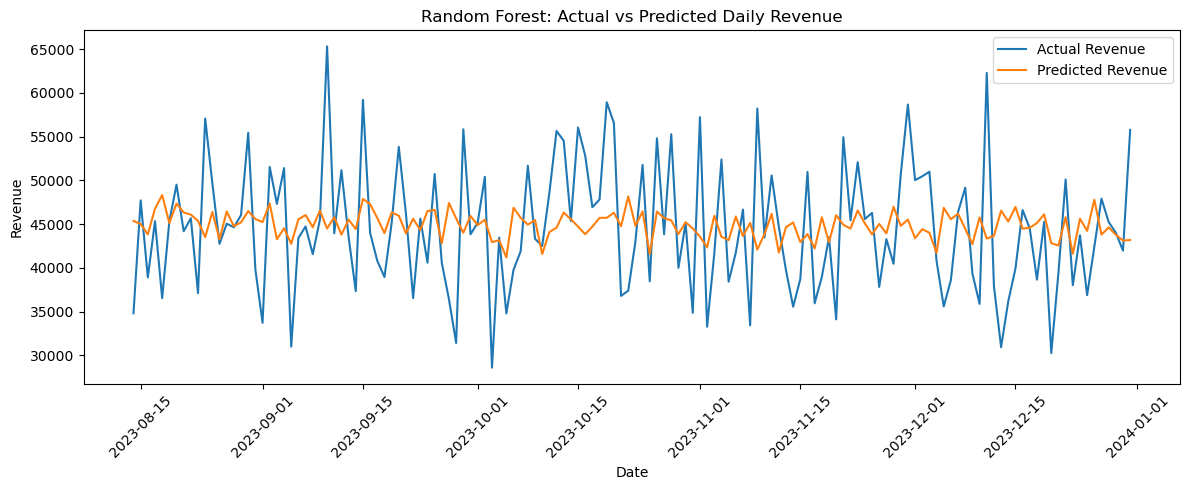

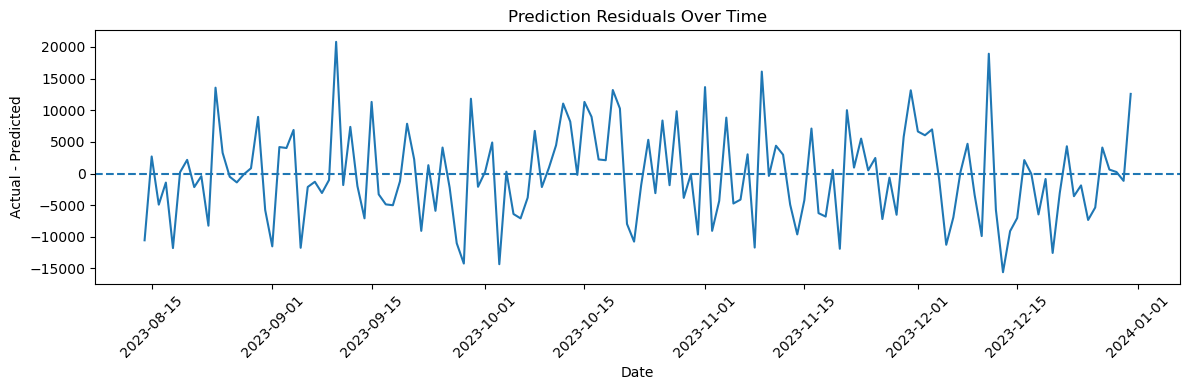


Final model and feature configuration saved!


In [7]:
# 1. Load feature-engineered data
data = pd.read_csv(r"../mini_project_by_3rd_person/data/processed/sales_features.csv")
data["order_date"] = pd.to_datetime(data["order_date"])
data = data.sort_values("order_date").reset_index(drop=True)

features = [
    "day_of_week", "day_of_month", "month", "quarter",
    "year", "is_weekend", "lag_1", "lag_7", "lag_14",
    "lag_30", "rolling_mean_7", "rolling_mean_30"
]

X = data[features]
y = data["daily_revenue"]

# 2. Recreate the original chronological split
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# 3. Train the selected configuration on training data
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# 4. Evaluate on the untouched test period
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

actual = y_test.to_numpy()
nonzero = actual != 0

mape = (
    np.mean(np.abs(
        (actual[nonzero] - predictions[nonzero])
        / actual[nonzero]
    )) * 100
    if nonzero.any() else np.nan
)

print("Final test MAE:", round(mae, 2))
print("Final test RMSE:", round(rmse, 2))
print("Final test MAPE (%):", round(mape, 2))

# 5. Build residual analysis table
results = pd.DataFrame({
    "order_date": data["order_date"].iloc[split_index:].to_numpy(),
    "actual_revenue": actual,
    "predicted_revenue": predictions
})

results["residual"] = (
    results["actual_revenue"] - results["predicted_revenue"]
)

print("\nResidual summary:")
print(results["residual"].describe())

print("\nLargest absolute errors:")
print(
    results.assign(
        absolute_error=results["residual"].abs()
    ).nlargest(10, "absolute_error")
)

# 6. Plot actual vs predicted revenue
plt.figure(figsize=(12, 5))
plt.plot(results["order_date"], results["actual_revenue"],
         label="Actual Revenue")
plt.plot(results["order_date"], results["predicted_revenue"],
         label="Predicted Revenue")
plt.title("Random Forest: Actual vs Predicted Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Plot residuals over time
plt.figure(figsize=(12, 4))
plt.plot(results["order_date"], results["residual"])
plt.axhline(0, linestyle="--")
plt.title("Prediction Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 8. Save the test predictions and report
os.makedirs(r"../mini_project_by_3rd_person/reports", exist_ok=True)

results.to_csv(
    r"../mini_project_by_3rd_person/reports/final_test_residuals.csv",
    index=False
)

# 9. Retrain final model using all available historical rows
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

# 10. Save model and feature configuration
os.makedirs(r"../mini_project_by_3rd_person/models", exist_ok=True)

joblib.dump(
    final_model,
    r"../mini_project_by_3rd_person/models/final_model.joblib"
)

joblib.dump(
    features,
    r"../mini_project_by_3rd_person/models/feature_columns.joblib"
)

print("\nFinal model and feature configuration saved!")


        Feature  Importance
         lag_30    0.144622
          lag_7    0.143235
         lag_14    0.134578
          lag_1    0.133523
 rolling_mean_7    0.118410
rolling_mean_30    0.109487
   day_of_month    0.078151
          month    0.056965
    day_of_week    0.050051
           year    0.016860
        quarter    0.010115
     is_weekend    0.004002


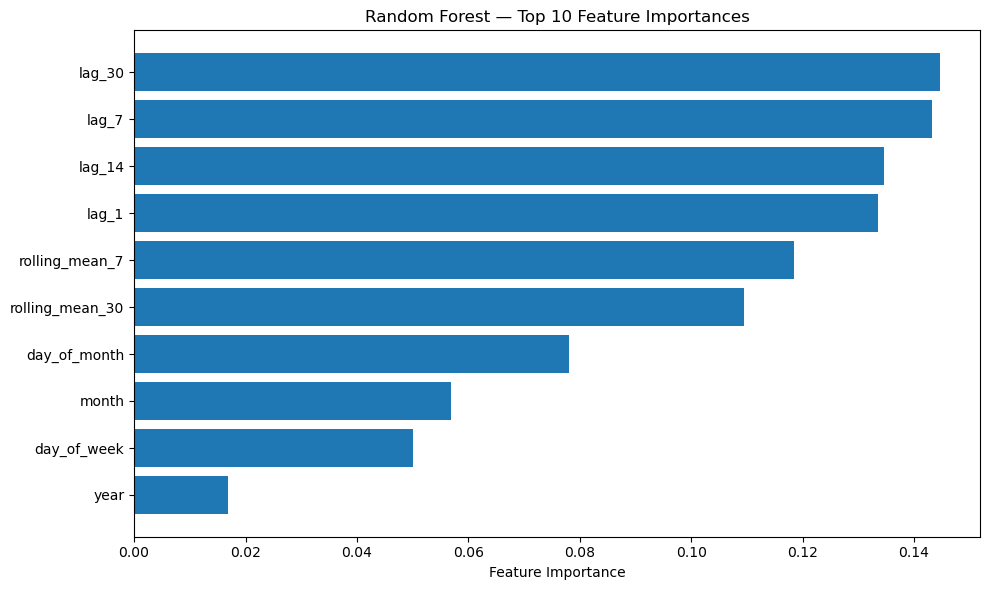

In [8]:

# Load the saved final model and feature names
model = joblib.load(r"../mini_project_by_3rd_person/models/final_model.joblib")
features = joblib.load(r"../mini_project_by_3rd_person/models/feature_columns.joblib")

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df.to_string(index=False))

# Plot the top features
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"].head(10)[::-1],
    importance_df["Importance"].head(10)[::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest — Top 10 Feature Importances")
plt.tight_layout()
plt.show()

# Save the results
importance_df.to_csv(
    r"../mini_project_by_3rd_person/reports/feature_importance.csv",
    index=False
)
